# Tutorial 01 · From "what happened?" to "what will happen?"
**Data Mining · HTW Berlin**

Last semester you **described** data: totals, averages, charts, dashboards.
This semester you will use data to **predict**: who will cancel, which machine will fail, which visitor will buy.

Today is an overview, no exercises. Just run the cells and look.

1. Last semester vs. this semester
2. The words of prediction
3. Our tools
4. What you will be able to predict
5. Test and compare
6. The CRISP-DM toolbox: methods and formulas per phase
7. What the tutorials look like

## 0 · Setup (just run)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.width", 120)
rng = np.random.default_rng(42)

---
## 1 · Last semester vs. this semester

| | Last semester | This semester |
|---|---|---|
| **Question** | What happened? | What will happen? |
| **Example** | How many customers cancelled last month? | **Which** customers will cancel next month? |
| **Answer** | one number or a chart for the whole company | a prediction **for each customer** |
| **Tools** | pandas, charts | pandas, charts **and models** |

Everything you learned last semester is still needed: before you can predict, you have to understand and clean the data.

---
## 2 · The words of prediction

| Word | Meaning | Example |
|---|---|---|
| **target** | what you want to predict | did the customer cancel? |
| **features** | what you know before | plan, months active, skipped deliveries |
| **model** | learns the link between features and target from past cases | |

| If the target is... | it is called... | example |
|---|---|---|
| a category (yes / no) | **classification** | churn, fraud, machine failure |
| a number | **regression** | price, demand |
| not given | **clustering** | customer groups |

---
## 3 · The libraries of the semester

| Library | What it does | Main use in this course | Modules |
|---|---|---|---|
| `pandas` | tables (DataFrames): load, filter, group, merge | every step that touches data | all |
| `numpy` | fast numbers and arrays, math functions | `log`, `sqrt`, random data, arrays | all |
| `matplotlib` | the basic plotting engine | figures, axes, layout | all |
| `seaborn` | statistical plots on top of matplotlib | histograms, boxplots, scatter, heatmaps | all |
| `scipy` | scientific statistics | `zscore`, distances, hierarchical clustering | 02, 13 |
| `scikit-learn` | machine learning | scaling, imputation, models, metrics, cross-validation | 03 to 13 |
| `imbalanced-learn` | resampling for rare classes | SMOTE, undersampling | 05 |
| `statsmodels` | classical statistics | regression with p-values and confidence intervals | 07 |
| `streamlit` | small web apps around an analysis | deployment demo | deployment |

Check your environment (every line should say OK; `streamlit` may be missing on Colab):

In [2]:
import importlib

toolbox = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
           "scipy": "scipy", "sklearn": "scikit-learn", "imblearn": "imbalanced-learn",
           "statsmodels": "statsmodels", "streamlit": "streamlit"}
missing = []
for module, pip_name in toolbox.items():
    try:
        m = importlib.import_module(module)
        print(f"OK       {pip_name:<17} {getattr(m, '__version__', '')}")
    except ImportError:
        print(f"MISSING  {pip_name:<17}")
        missing.append(pip_name)
if missing:
    print("\nInstall with:  pip install " + " ".join(missing))

OK       pandas            3.0.5
OK       numpy             2.5.3
OK       matplotlib        3.11.2
OK       seaborn           0.13.2
OK       scipy             1.18.1
OK       scikit-learn      1.9.1
MISSING  imbalanced-learn 
MISSING  statsmodels      
MISSING  streamlit        

Install with:  pip install imbalanced-learn statsmodels streamlit


**One pattern for all models.** Every scikit-learn tool is used the same way, so a new method is just a new name:

```python
model = LogisticRegression()    # 1. create
model.fit(X, y)                 # 2. learn from past data
model.predict(X_new)            # 3. predict new cases
```

---
## 4 · What you will be able to predict
Six short examples from **six different businesses**, each with its own small dataset. Before each demo, a **"The data"** line tells you what one row is. You do not need to understand the code yet, the methods come week by week in the lecture.

The datasets are **mock data** (fake, but realistic), created in the next cell. Just run it.

In [3]:
# Mock data for the gallery. Just run this cell.
# Each function creates a fake dataset. The comment says which rule is hidden in the data.

def make_customers(n=600):
    """Coffee subscription customers. Rule: many skipped deliveries and support tickets -> more churn,
    long-time customers and the Office plan -> less churn. Age has NO effect."""
    plan = rng.choice(["Basic", "Plus", "Office"], n, p=[.55, .35, .10])
    months = rng.integers(1, 37, n)
    skipped = rng.poisson(.8, n)
    tickets = rng.poisson(.6, n)
    age = rng.normal(36, 10, n).round().clip(18, 75)
    risk = -2.2 + 1.4 * skipped + .8 * tickets - .08 * months + .5 * (plan == "Basic") - 1.2 * (plan == "Office")
    churned = (rng.random(n) < 1 / (1 + np.exp(-risk))).astype(int)
    return pd.DataFrame({"plan": plan, "months_active": months, "skipped_deliveries": skipped,
                         "support_tickets": tickets, "age": age, "churned": churned})


def make_leads(n=500):
    """Website visitors. Rule: ordering a free sample, viewing more pages and coming from a referral -> more likely to buy."""
    source = rng.choice(["Instagram", "Google Ads", "Referral", "Newsletter"], n, p=[.35, .3, .15, .2])
    pages = rng.poisson(4, n) + 1
    minutes = rng.gamma(2, 2.5, n).round(1)
    tried_sample = rng.random(n) < .3
    chance = -3 + .25 * pages + .12 * minutes + 1.6 * tried_sample + 1.0 * (source == "Referral")
    became_client = (rng.random(n) < 1 / (1 + np.exp(-chance))).astype(int)
    return pd.DataFrame({"source": source, "pages_viewed": pages, "minutes_on_site": minutes,
                         "ordered_free_sample": tried_sample.astype(int), "became_client": became_client})


def make_machines(n=1500):
    """Production machines. Rule: failures are RARE; unusual temperature, strong vibration and many hours -> more failures."""
    temp = rng.normal(70, 5, n)
    vibration = rng.normal(3, .6, n)
    hours = rng.integers(100, 9000, n)
    risk = -6.5 + .06 * (temp - 70) ** 2 / 4 + 1.2 * (vibration - 3) * 2 + hours / 3000
    failure = (rng.random(n) < 1 / (1 + np.exp(-risk))).astype(int)
    return pd.DataFrame({"temperature": temp.round(1), "vibration": vibration.round(2),
                         "operating_hours": hours, "failure_30d": failure})


def make_transactions(n=800):
    """Card payments. Rule: 800 normal payments during the day, plus 12 large payments in the night (suspicious)."""
    normal_amount = rng.gamma(2, 25, n)
    normal_hour = rng.normal(15, 3, n) % 24
    odd_amount = rng.uniform(400, 900, 12)
    odd_hour = rng.uniform(1, 5, 12)
    return pd.DataFrame({"amount_eur": np.r_[normal_amount, odd_amount].round(2),
                         "hour_of_day": np.r_[normal_hour, odd_hour].round(1)})


def make_segments(n=400):
    """Shop customers. Rule: three hidden groups (few small orders / many medium orders / few large orders)."""
    centers = np.array([[2, 15], [8, 25], [4, 60]])
    group = rng.integers(0, 3, n)
    points = centers[group] + rng.normal(0, [1.0, 5], (n, 2))
    return pd.DataFrame({"orders_per_month": points[:, 0].clip(0.5).round(1),
                         "avg_basket_eur": points[:, 1].clip(5).round(1)})


print("mock datasets ready")

mock datasets ready


### 4.1 · Churn: who will cancel?
| | |
|---|---|
| **Question** | Which current customers will cancel next month? |
| **Target** | `churned` (yes / no) → classification |
| **Methods** | logistic regression (module 07), decision trees (11), SVM / LDA (12) |
| **Typical use** | send a retention offer to the customers with the highest risk |

**The data:** 600 customers of a coffee subscription (*Kiezbohne*). One row = one customer: plan, months active, skipped deliveries, support tickets, age, and whether they cancelled.

The model learns from **last year's** customers (we know who cancelled) and predicts for **today's** customers (nobody knows yet).

**The table.** Each row is one customer from last year. The model looks at the five **feature** columns and learns to predict the **target** column.

| Column | Meaning | Role |
|---|---|---|
| `plan` | Basic (250 g/month), Plus (500 g) or Office (2 kg) | feature |
| `months_active` | how long the person has been a customer | feature |
| `skipped_deliveries` | how often they paused a delivery | feature |
| `support_tickets` | how often they contacted support | feature |
| `age` | age of the customer | feature |
| `churned` | 1 = cancelled, 0 = stayed | **target**, what we predict |

In [4]:
past_customers = make_customers()          # last year's customers: we already know who cancelled
print(f"{len(past_customers)} customers, {past_customers['churned'].sum()} of them cancelled")
past_customers.head(8)

600 customers, 130 of them cancelled


,plan,months_active,skipped_deliveries,support_tickets,age,churned
0,Plus,32,1,0,32.0,0
1,Basic,18,0,1,33.0,0
2,Plus,36,2,0,28.0,0
3,Plus,28,1,0,40.0,0
4,Basic,24,0,1,35.0,0
5,Office,33,0,0,29.0,0
6,Plus,19,6,1,29.0,1
7,Plus,26,0,1,24.0,0


Now the model learns from this table and predicts five of **today's** customers, for whom we do not know the answer yet.

In [5]:
from sklearn.linear_model import LogisticRegression

# learn from last year's customers
X = pd.get_dummies(past_customers.drop(columns="churned"), drop_first=True)
model = LogisticRegression(max_iter=1000).fit(X, past_customers["churned"])

# today: five customers, nobody knows yet
today = pd.DataFrame({
    "plan":               ["Basic", "Office", "Plus", "Basic", "Plus"],
    "months_active":      [2, 30, 14, 8, 25],
    "skipped_deliveries": [3, 0, 1, 2, 0],
    "support_tickets":    [2, 0, 1, 0, 0],
    "age":                [24, 45, 37, 31, 52],
}, index=["Lena", "Firma Kunz", "Mehmet", "Sofia", "Jonas"])
X_today = pd.get_dummies(today, drop_first=True).reindex(columns=X.columns, fill_value=0)

today["churn_risk"] = model.predict_proba(X_today)[:, 1].round(2)
today.sort_values("churn_risk", ascending=False)

,plan,months_active,skipped_deliveries,support_tickets,age,churn_risk
Lena,Basic,2,3,2,24,0.99
Sofia,Basic,8,2,0,31,0.65
Mehmet,Plus,14,1,1,37,0.20
Jonas,Plus,25,0,0,52,0.01
Firma Kunz,Office,30,0,0,45,0.00


**What to notice:** the marketing team now knows whom to call first (Lena) and whom not to worry about (Firma Kunz).

### 4.2 · New clients: which leads will convert?
| | |
|---|---|
| **Question** | Which website visitors will become paying clients? |
| **Target** | `became_client` (yes / no) → classification |
| **Methods** | decision trees (module 11), logistic regression (07) |
| **Typical use** | sales calls only to the most promising leads ("lead scoring") |

**The data:** 500 visitors of an online shop. One row = one visitor: where they came from, pages viewed, minutes on the site, whether they ordered a free sample, and whether they became a client.

**Before you run, guess:** you can only call 50 of 500 visitors. Who do you call? The ones from Instagram? The ones who stayed longest on the site? The ones who ordered a free sample?

A **decision tree** finds the answer by itself and gives it back as **rules you can read**.

In [6]:
from sklearn.tree import DecisionTreeClassifier

leads = make_leads()
X = pd.get_dummies(leads.drop(columns="became_client"), drop_first=True)
y = leads["became_client"]

tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=30, random_state=42).fit(X, y)


def rules_in_words(tree, X, y):
    """Translate each final group of the tree into a sentence and count how many visitors bought."""
    t, rows = tree.tree_, []

    def walk(node, conditions):
        if t.children_left[node] == -1:
            mask = np.ones(len(X), dtype=bool)
            words = []
            for col, thr, left in conditions:
                mask &= (X[col] <= thr).to_numpy() if left else (X[col] > thr).to_numpy()
                if set(X[col].unique()) <= {0, 1}:
                    words.append(f"{col} = {'no' if left else 'yes'}")
                else:
                    words.append(f"{col} {'<=' if left else '>'} {thr:.1f}")
            rows.append({"rule": " AND ".join(words), "visitors": int(mask.sum()),
                         "became client": round(100 * y[mask].mean())})
            return
        col, thr = X.columns[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conditions + [(col, thr, True)])
        walk(t.children_right[node], conditions + [(col, thr, False)])

    walk(0, [])
    table = pd.DataFrame(rows).sort_values("became client", ascending=False).reset_index(drop=True)
    table["became client"] = table["became client"].astype(str) + "%"
    return table


print(f"Overall, {y.mean():.0%} of the visitors became clients.\n")
rules_in_words(tree, X, y)

Overall, 36% of the visitors became clients.



,rule,visitors,became client
0,ordered_free_sample = yes AND pages_viewed > 4.5,76,74%
1,ordered_free_sample = no AND minutes_on_site >...,47,57%
2,ordered_free_sample = yes AND pages_viewed <= 4.5,62,47%
3,ordered_free_sample = no AND minutes_on_site <...,315,22%


**What to notice:** nobody told the tree that the free sample matters. It found it by itself. Was your guess right?

### 4.3 · Predictive maintenance: which machine will fail?
| | |
|---|---|
| **Question** | Which machines will fail in the next 30 days? |
| **Target** | `failure_30d` (yes / no) → classification with a **rare** class |
| **Methods** | any classifier + balancing (module 05) + the confusion matrix (09) |
| **Typical use** | plan maintenance before the failure |

**The data:** 1,500 production machines. One row = one machine: temperature, vibration, operating hours, and whether it failed within 30 days.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

machines = make_machines()
print(f"Only {machines['failure_30d'].mean():.1%} of the machines failed.\n")

X, y = machines.drop(columns="failure_30d"), machines["failure_30d"]
X_train, X_check, y_train, y_check = train_test_split(X, y, test_size=0.4, stratify=y, random_state=0)
scaler = StandardScaler().fit(X_train)

rows = []
for name, weight in [("normal model", None), ("balanced model", "balanced")]:
    m = LogisticRegression(max_iter=1000, class_weight=weight).fit(scaler.transform(X_train), y_train)
    pred = m.predict(scaler.transform(X_check))
    rows.append({"model": name,
                 "accuracy": f"{(pred == y_check).mean():.0%}",
                 "failures found": f"{((pred == 1) & (y_check == 1)).sum()} of {y_check.sum()}",
                 "false alarms": int(((pred == 1) & (y_check == 0)).sum())})
pd.DataFrame(rows)

Only 3.6% of the machines failed.



,model,accuracy,failures found,false alarms
0,normal model,96%,1 of 22,0
1,balanced model,81%,17 of 22,109


**What to notice:** the normal model looks 96% "accurate" but finds almost no failures. When we tell the model that the rare failures matter (**balancing**, module 05), it finds most of them, with more false alarms. Which error is more expensive is a business decision (module 09).

### 4.4 · Fraud and anomalies: what looks unusual?
| | |
|---|---|
| **Question** | Which transactions look different from the normal pattern? |
| **Target** | often **no label** at the start → anomaly detection |
| **Methods** | z-score, IQR, Isolation Forest, LOF (module 02) |
| **Typical use** | send the most unusual cases to a human for review |

**The data:** 812 card payments. One row = one payment: amount and hour of the day. There is **no label**: nobody tells us which payments are fraud.

**What to notice:** the model flags points without knowing what fraud is. It only knows what is *unusual*.

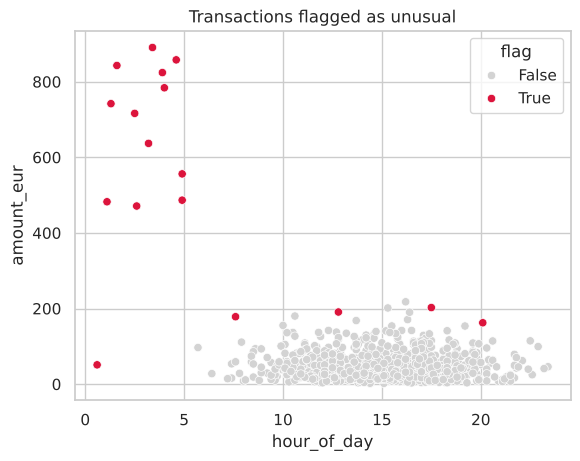

In [8]:
from sklearn.ensemble import IsolationForest

tx = make_transactions()
tx["flag"] = IsolationForest(contamination=0.02, random_state=42).fit_predict(tx) == -1

sns.scatterplot(data=tx, x="hour_of_day", y="amount_eur", hue="flag", palette={False: "lightgrey", True: "crimson"})
plt.title("Transactions flagged as unusual")
plt.show()

### 4.5 · Segmentation: which groups of customers exist?
| | |
|---|---|
| **Question** | Are there natural groups of customers with similar behaviour? |
| **Target** | **none** → clustering (unsupervised) |
| **Methods** | k-means, hierarchical clustering (module 13) |
| **Typical use** | different marketing for each group |

**The data:** 400 shop customers. One row = one customer: orders per month and average basket in EUR. There is **no target**.

**What to notice:** nobody told the algorithm the groups. It found them from the data. Naming them ("bulk buyers", "premium") is the analyst's job.

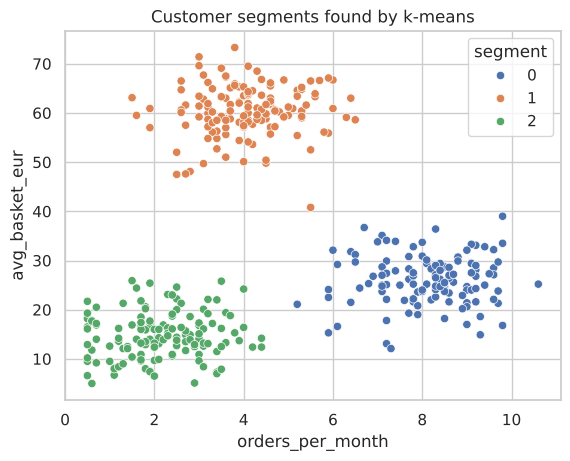

In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

seg = make_segments()
seg["segment"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(StandardScaler().fit_transform(seg))

sns.scatterplot(data=seg, x="orders_per_month", y="avg_basket_eur", hue="segment", palette="deep")
plt.title("Customer segments found by k-means")
plt.show()

### 4.6 · Choosing variables: which features matter?
| | |
|---|---|
| **Question** | Which variables carry the most information about the target? Which can we drop? |
| **Target** | same as the prediction problem (here: churn) |
| **Methods** | correlation filters, variance filters (module 06), feature selection, PCA, factor analysis (08), importance from tree models like random forest (11) |
| **Typical use** | simpler, cheaper, more explainable models |

**The data:** the same 600 coffee subscription customers as in 4.1.

While learning, the model gives every variable a **weight**: how much it pushes the churn risk up or down. In the mock data, **age has no effect**. Does the model notice?

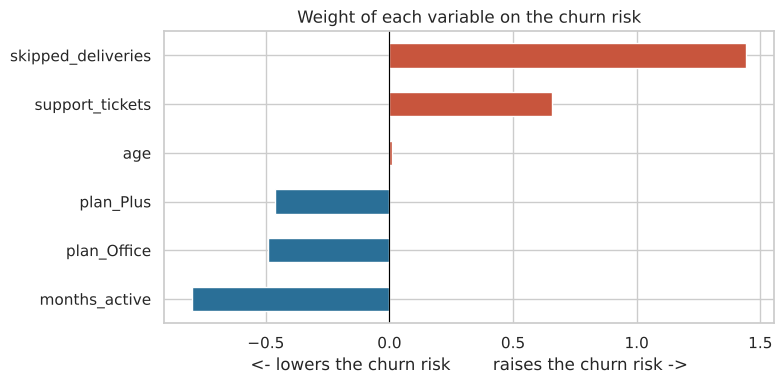

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X = pd.get_dummies(past_customers.drop(columns="churned"), drop_first=True).astype(float)
X_scaled = StandardScaler().fit_transform(X)        # same scale for all variables, so the weights are comparable
weights_model = LogisticRegression(max_iter=1000).fit(X_scaled, past_customers["churned"])

weights = pd.Series(weights_model.coef_[0], index=X.columns).sort_values()
colors = ["#2a6f97" if w < 0 else "#c8553d" for w in weights]
ax = weights.plot(kind="barh", color=colors, figsize=(8, 4))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Weight of each variable on the churn risk")
ax.set_xlabel("<- lowers the churn risk        raises the churn risk ->")
plt.tight_layout()
plt.show()

**What to notice:** red bars raise the risk, blue bars lower it, and **age is almost zero**: the model found out by itself that age does not help. Choosing the useful variables is modules 06 and 08.

---
## 5 · Test and compare

We go back to the **coffee subscription** from 4.1, with a bigger sample of **2,000 customers**. The question stays the same: *which customers will cancel?*

This semester we do not stop at "the model works". We **measure** it on customers it has never seen, **compare** it with other options, and **tune** it until it fits the goal. Two everyday tools for that:
- **5.1** compare two methods on the same test customers
- **5.2** a **threshold sweep**: try many cut-offs and see what each one costs

In [11]:
# Helper for this section. Just run it.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

data = make_customers(2000)
X = pd.get_dummies(data.drop(columns="churned"), drop_first=True).astype(float)
y = data["churned"]

# learn from 70% of the customers, test on the other 30% (customers the models never saw)
X_learn, X_test, y_learn, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

logreg = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_learn, y_learn)
tree = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_learn, y_learn)


def count_results(truth, pred):
    """Count the four possible outcomes of a yes/no prediction."""
    return {"found (cancelled, predicted cancel)": int(((pred == 1) & (truth == 1)).sum()),
            "missed (cancelled, predicted stay)":  int(((pred == 0) & (truth == 1)).sum()),
            "false alarm (stayed, predicted cancel)": int(((pred == 1) & (truth == 0)).sum()),
            "correct stay (stayed, predicted stay)":  int(((pred == 0) & (truth == 0)).sum())}


print(f"{len(X_learn)} customers to learn from, {len(X_test)} test customers ({int(y_test.sum())} of them really cancelled)")

1400 customers to learn from, 600 test customers (128 of them really cancelled)


**What the models see.** The same kind of table as in 4.1, now with 2,000 customers. Both methods get **the same five feature columns** and must predict `churned`.

In [12]:
print(f"{len(data)} customers, {data['churned'].sum()} cancelled ({data['churned'].mean():.0%})")
print(f"{len(X_learn)} rows to learn from, {len(X_test)} rows hidden for the test ({int(y_test.sum())} of them cancelled)")
data.head(8)

2000 customers, 426 cancelled (21%)
1400 rows to learn from, 600 rows hidden for the test (128 of them cancelled)


,plan,months_active,skipped_deliveries,support_tickets,age,churned
0,Basic,26,1,0,36.0,0
1,Basic,14,1,0,23.0,1
2,Basic,27,0,0,38.0,0
3,Plus,19,1,1,42.0,0
4,Office,9,0,0,18.0,0
5,Basic,1,2,1,23.0,0
6,Plus,1,1,1,45.0,0
7,Basic,9,0,0,43.0,0


### 5.1 · Two methods, same test customers
Every prediction ends in one of four boxes. We count the boxes for both methods and put them side by side.

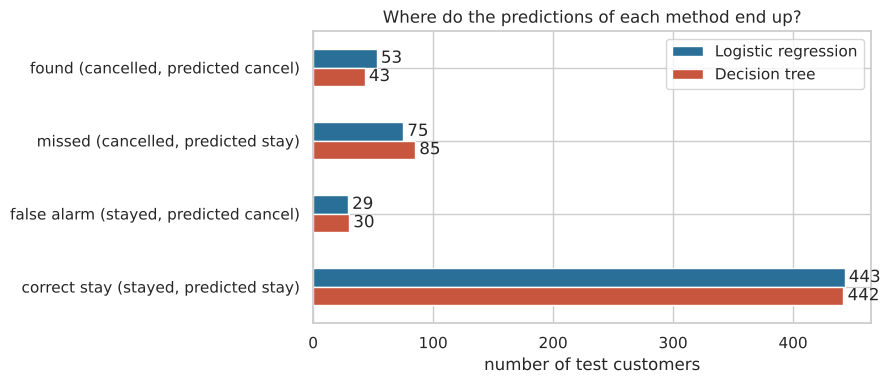

,Logistic regression,Decision tree
"found (cancelled, predicted cancel)",53,43
"missed (cancelled, predicted stay)",75,85
"false alarm (stayed, predicted cancel)",29,30
"correct stay (stayed, predicted stay)",443,442


In [13]:
comparison = pd.DataFrame({
    "Logistic regression": count_results(y_test, logreg.predict(X_test)),
    "Decision tree":       count_results(y_test, tree.predict(X_test)),
})

ax = comparison.plot(kind="barh", figsize=(9, 4), color=["#2a6f97", "#c8553d"])
ax.invert_yaxis()
ax.set_xlabel("number of test customers")
ax.set_title("Where do the predictions of each method end up?")
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()
comparison

**What to notice:** both methods are right for almost all customers who stay. The difference is in the top two boxes: with the same number of false alarms, **logistic regression finds 10 more cancellers** (53 vs 43). Comparing the boxes, not one overall score, shows *where* each method makes its mistakes.

But both still **miss** more cancellers than they find. Can we fix that without changing the method? Yes, see 5.2. This picture is called a **confusion matrix** (module 09).

### 5.2 · Threshold sweep: where do we cut?
A model does not say "cancel" or "stay". It gives a **risk** between 0 and 1, and **we** choose the cut-off: above it, the customer gets a retention offer. The default is 0.5, but nothing forces us to use it. Let us try them all and draw two lines:

- **red:** of all customers who really cancelled, how many get an offer (= are found)
- **blue:** of all customers, how many get an offer (= how much the campaign costs)

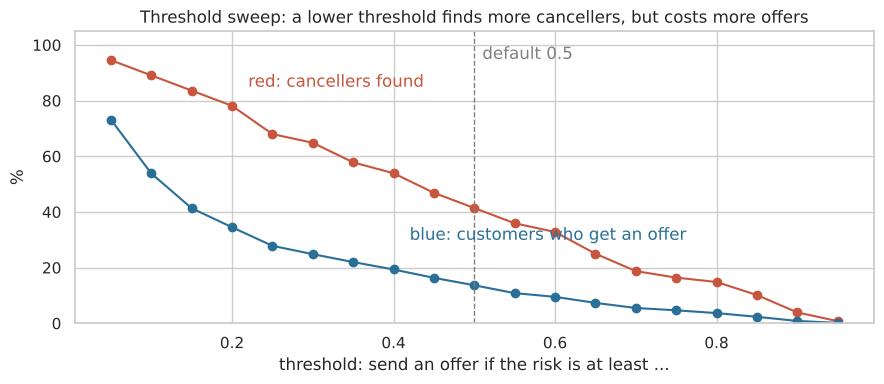

,cancellers found (%),customers who get an offer (%)
threshold,,
0.2,78.0,34.0
0.3,65.0,25.0
0.5,41.0,14.0
0.7,19.0,6.0


In [14]:
risk = logreg.predict_proba(X_test)[:, 1]

sweep = []
for threshold in np.arange(0.05, 0.96, 0.05):
    offer = risk >= threshold
    sweep.append({"threshold": round(threshold, 2),
                  "cancellers found (%)": 100 * (offer & (y_test == 1)).sum() / (y_test == 1).sum(),
                  "customers who get an offer (%)": 100 * offer.mean()})
sweep = pd.DataFrame(sweep).set_index("threshold")

ax = sweep.plot(color=["#c8553d", "#2a6f97"], marker="o", figsize=(9, 4), legend=False)
ax.set_ylim(0, 105)
ax.set_ylabel("%")
ax.set_xlabel("threshold: send an offer if the risk is at least ...")
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1)
ax.text(0.51, 95, "default 0.5", color="grey")
ax.text(0.22, 85, "red: cancellers found", color="#c8553d")
ax.text(0.42, 30, "blue: customers who get an offer", color="#2a6f97")
ax.set_title("Threshold sweep: a lower threshold finds more cancellers, but costs more offers")
plt.tight_layout()
plt.show()
sweep.loc[[0.2, 0.3, 0.5, 0.7]].round(0)

**How to read it:** at the default 0.5, offers go to 14% of the customers and we find 41% of the cancellers. At 0.2, offers go to 35% of the customers and we find 79% of the cancellers.

**What to notice:**
- A **low threshold** finds almost every canceller, but sends offers to many customers who would have stayed.
- A **high threshold** sends few offers, but misses most cancellers.
- There is no "correct" threshold in the data. If an offer costs 5 EUR and a lost customer costs 300 EUR, a low threshold is worth it. The **business costs** choose the point on the curve.

This is the routine of the semester: **measure, compare, sweep, decide**, always with a chart.

---
## 6 · The CRISP-DM toolbox: methods and formulas per phase
The Moodle quiz maps *tasks* to phases. Here are the **methods of this semester**, with their formula or idea, the Python function and the module, sorted by the phase where you use them.

### Data Understanding
| Method | Formula / idea | Python | Module |
|---|---|---|---|
| Summary statistics | mean $\bar{x} = \frac{1}{n}\sum x_i$, median, standard deviation $s$ | `df.describe()` | 01 |
| Correlation | $r = \frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum (x_i-\bar{x})^2 \sum (y_i-\bar{y})^2}}$ | `df.corr()` | 01, 06 |
| Visual checks | histogram, boxplot, scatter | `sns.histplot`, `sns.boxplot` | all |

### Data Preparation
| Method | Formula / idea | Python | Module |
|---|---|---|---|
| z-score outliers | $z = \frac{x - \bar{x}}{s}$, flag $\lvert z\rvert > 3$ | `scipy.stats.zscore` | 02 |
| IQR outliers | outside $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$ | `df.quantile()` | 02 |
| Log transform | $x' = \log(x)$ for right-skewed, positive data | `np.log` | 02, 03 |
| Standardisation | $x' = \frac{x - \bar{x}}{s}$ | `StandardScaler` | 03 |
| Min-max scaling | $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$ | `MinMaxScaler` | 03 |
| Imputation | replace missing by mean, median, neighbours | `SimpleImputer`, `KNNImputer` | 04 |
| Balancing | over-sample the rare class (SMOTE) or under-sample the large one | `imblearn` | 05 |
| Rough reduction | drop near-constant or highly correlated variables | `VarianceThreshold`, `df.corr()` | 06 |
| Feature selection / PCA / factor analysis | keep the informative variables, or combine them into few components | `SelectKBest`, `PCA`, `FactorAnalysis` | 08 |

### Modeling
| Method | Formula / idea | Python | Module |
|---|---|---|---|
| Logistic regression | $P(y=1) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$ | `LogisticRegression` | 07 |
| Decision tree | split where impurity drops most, Gini $= 1 - \sum p_k^2$ | `DecisionTreeClassifier` | 11 |
| Random forest | many trees on random samples, majority vote | `RandomForestClassifier` | 11 |
| SVM | the boundary with the widest margin between classes | `SVC` | 12 |
| LDA | linear combination of features that separates classes best | `LinearDiscriminantAnalysis` | 12 |
| k-means | minimise $\sum_{k}\sum_{x \in C_k} \lVert x - \mu_k \rVert^2$ | `KMeans` | 13 |

### Evaluation
| Method | Formula / idea | Python | Module |
|---|---|---|---|
| Confusion matrix | counts of TP, FP, FN, TN: the four boxes from 5.1 (found, false alarm, missed, correct stay) | `confusion_matrix` | 09 |
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | `accuracy_score` | 09 |
| Precision | $\frac{TP}{TP + FP}$: of the flagged cases, how many are right? | `precision_score` | 09 |
| Recall | $\frac{TP}{TP + FN}$: of the real cases, how many did we find? | `recall_score` | 09 |
| F1 | $2 \cdot \frac{precision \cdot recall}{precision + recall}$ | `f1_score` | 09 |
| k-fold cross-validation | train on $k-1$ parts, test on the remaining one, repeat $k$ times | `cross_val_score` | 10 |

### Deployment
| Method | Idea | Python |
|---|---|---|
| Scoring new cases | apply the trained model to new data | `model.predict_proba(new_X)` |
| Saving a model | store it to reuse without retraining | `joblib.dump(model, "model.pkl")` |
| Small app | a web page around the model | `streamlit` |
| Monitoring | rerun quality checks and compare predictions with reality | your own functions |

> **Note:** some methods fit two phases. A recall score checks a model technically (*Modeling: Assess Model*), but **Evaluation** asks a different question: does the model meet the **business** goal? The phase is defined by *why* you use a method, not by the method itself.

---
## 7 · What the tutorials look like
Every week one notebook on the topic of the lecture, with small realistic datasets (Berlin rents, a coffee subscription club, sensor data). Each task has a level (`[basic]`, `[medium]`, `[challenge]`), hidden hints and a check that tells you if you are on the right track.

**Until next week:** think of a company or dataset you know. What could you **predict** there, and what would you need to know beforehand?